In [48]:
from skyfield.api import load, wgs84
import numpy as np
from numpy import array2string
from datetime import datetime, timedelta
import os
from scipy import io as sio
import pytz
import math

In [49]:
# TODO: define constants and set other parameters
c = 299792458.0 # speed of light in m/s
fc = 11.575e9 # carrier frequency in Hz
f = 0.2e6 # narrowband tone freq in Hz
lo = 9.75e9 # local oscillator frequency in Hz
fs = 1e6 # sampling frequency in Hz
lam = c/fc # wavelength in m
d = lam/2 # antenna spacing in m
re = 6378e3 # earth radius in m
min_elevation = 60 # minimum elevation of visible sats


In [58]:
# Load tle from path

# change the path
path = '/Users/ishani/UIUC/Research/starlink_ofdm/AoA_Sim/tles/10_31/STARLINK-6150.tle'
# path = 'D:\\Desktop\\study\\2023_summer\\starlink_ofdm\\AoA_Sim\\tles\\10_31\\STARLINK-6150.tle'

satellites = load.tle_file(path)
print(satellites)

# % assume we have 4 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB4 |       W + E
# | LNB1 LNB3 |         S
#  ------------
# initialize location of 4 LNBs with lat, lon = +40.11389690596162, -88.22484814695467 (UIUC)
lat_1, lon_1 = +40.11389690596162, -88.22484814695467
lnb_1 = wgs84.latlon(lat_1, lon_1)
lnb_2 = wgs84.latlon(lat_1+math.degrees(d/re), lon_1)
lnb_3 = wgs84.latlon(lat_1, lon_1+math.degrees(d/re)/math.cos(math.radians(lat_1)))
lnb_4 = wgs84.latlon(lat_1+math.degrees(d/re), lon_1+math.degrees(d/re)/math.cos(math.radians(lat_1)))
lnbs = [lnb_1, lnb_2, lnb_3, lnb_4]

# set start time and stop time, add 5 hours to account for time zone difference
ts = load.timescale()
start_time = datetime(2023, 10, 31, 0, 0, 0, tzinfo=pytz.UTC)+timedelta(hours=5) 
stop_time = datetime(2023, 10, 31, 0, 1, 0, tzinfo=pytz.UTC)+timedelta(hours=5)

[<EarthSatellite STARLINK-6150 catalog #57119 epoch 2023-10-31 06:43:42 UTC>]


The following section tries to estimate the AoA (both azimuth & elevation) using MUSIC.

Assume that the satellite is transmitting at frequency $f_c+f=11.575 GHz+0.2 MHz$, i.e.,
$$y(t) = \exp(j2\pi(f+f_c)t),$$
where $f_c$ is the carrier frequency and $f$ is the narrowband tone's frequency.

Assume when it arrives at LNB-1 at UIUC, it becomes 
$$y_1(t) = A\exp(j2\pi(f+f_c)t)+n_1,$$
where $A$ is path loss, $n_1$ is the noise at LNB-1.

Similarly, for LNB-i (i=2,3,4), there will be time delays since the distance between LNB-i will be different from LNB-1, given by
$$y_i(t) = A\exp(j2\pi(f+f_c)\times (t-(r_i-r_1)/c))+n_i, \\
 = A\exp(-j2\pi(f+f_c)*(r_i-r_1)/c)\times \exp(j2\pi(f+f_c)t)+n_i, \\
 = A'\exp(j2\pi(f+f_c)t)+n_i,$$
where $r_i$ is the distance between the sat and the i-th LNB. If $r_i>r_1$ then it arrives later. Also assume that $A$ is same for different LNBs since they are very close to each other.

$y_i(t)$ is in anaglog domain, then LNB \& USRP down-converts it at sample it. In the most ideal case where we have synchronized LNBs and USRPs, the digital signal we get is removing $f_c$ and substituting continuous time $t$ with discrete time samples $n*T_s = n/F_s$, i.e.,
$$y_i[n] = A'\exp(j2\pi f n/f_s)+n_i,$$
from where we start our simulation

In [66]:
# get start time as ts.utc
t = ts.utc(start_time)
n = np.arange(0, fs, 1)
i = 0
received_sig_1 = np.empty(len(n), dtype=complex)
received_sig_2 = np.empty(len(n), dtype=complex)
received_sig_3 = np.empty(len(n), dtype=complex)
received_sig_4 = np.empty(len(n), dtype=complex)
while True:
    dist1 = (satellites[0]-lnb_1).at(t)
    el1, az1, distance1 = dist1.altaz()
    # print time, elevation, azimuth, latitude, longitude
    # print(t.utc_iso(), el1.degrees, az1.degrees)
    _, _, the_range1, _, _, range_rate1 = dist1.frame_latlon_and_rates(lnb_1)
    doppler_shift1 = (fc)*range_rate1.km_per_s*1000/c

    dist2 = (satellites[0]-lnb_2).at(t)
    el2, az2, distance2 = dist2.altaz()
    # print time, elevation, azimuth, latitude, longitude
    # print(t.utc_iso(), el2.degrees, az2.degrees)
    _, _, the_range2, _, _, range_rate2 = dist2.frame_latlon_and_rates(lnb_2)
    doppler_shift2 = (fc)*range_rate2.km_per_s*1000/c

    dist3 = (satellites[0]-lnb_3).at(t)
    el3, az3, distance3 = dist3.altaz()
    # print time, elevation, azimuth, latitude, longitude
    # print(t.utc_iso(), el3.degrees, az3.degrees)
    _, _, the_range3, _, _, range_rate3 = dist3.frame_latlon_and_rates(lnb_3)
    doppler_shift3 = (fc)*range_rate3.km_per_s*1000/c

    dist4 = (satellites[0]-lnb_4).at(t)
    el4, az4, distance4 = dist4.altaz()
    # print time, elevation, azimuth, latitude, longitude
    # print(t.utc_iso(), el4.degrees, az4.degrees)
    _, _, the_range4, _, _, range_rate4 = dist4.frame_latlon_and_rates(lnb_4)
    doppler_shift4 = (fc)*range_rate4.km_per_s*1000/c

    print(doppler_shift1, doppler_shift2, doppler_shift3, doppler_shift4)
    print(the_range1.km, the_range2.km, the_range3.km, the_range4.km)
    # generate received signal TODO: double check
    # received_sig_0 = np.exp(-1j*2*np.pi*(fc+f+doppler_shift)*(n[i]/fs+the_range.km/c)) # TODO: can comment this out
    # downconvert to baseband : for now we assume that the effect of doppler shift is equivalent on all lnbs and will cancel out when calculating phase difference
    # TODO: add effect of doppler shift
    received_sig_1[i] = np.exp(-1j*2*np.pi*f*n[i]/fs)*np.exp(1j*2*np.pi*(fc+doppler_shift1)*the_range1.km/c) 
    received_sig_2[i] = np.exp(-1j*2*np.pi*f*n[i]/fs)*np.exp(1j*2*np.pi*(fc+doppler_shift2)*the_range2.km/c)
    received_sig_3[i] = np.exp(-1j*2*np.pi*f*n[i]/fs)*np.exp(1j*2*np.pi*(fc+doppler_shift3)*the_range3.km/c)
    received_sig_4[i] = np.exp(-1j*2*np.pi*f*n[i]/fs)*np.exp(1j*2*np.pi*(fc+doppler_shift4)*the_range4.km/c)

    # plot phase difference between received signals
    

    # TODO: replicate code for more antennas

    # TODO: get phase difference between antennas

    #TODO: get AoA

    # increment t which is ts.utc by 1 second
    t = ts.utc(t.utc_datetime()+timedelta(seconds=1))
    i += 1
    print(i)

    if t.utc_datetime() > stop_time:
        break


-63736.1448188342 -63736.142987613275 -63736.150407184294 -63736.14857596325
579.1845606976374 579.18455967812 579.1845637505538 579.184562731037
1
-60715.777298301306 -60715.77545102538 -60715.782933429255 -60715.781086153394
577.5728577117314 577.5728567398526 577.5728606193004 577.5728596474216
2
-57670.566456556284 -57670.56459381076 -57670.572136656614 -57670.570273911115
576.0397061031229 576.0397051792895 576.0397088641556 576.0397079403225
3
-54601.50590407475 -54601.50402647403 -54601.511627255786 -54601.50974965509
574.5857365467112 574.5857356713171 574.5857391600671 574.585738284673
4
-51509.63519316485 -51509.633301351096 -51509.64095745066 -51509.639065636926
573.2115533855691 573.2115525589904 573.2115558501582 573.2115550235791
5
-48396.03859628708 -48396.03669093018 -48396.04439962058 -48396.04249426365
571.9177334563323 571.9177326789281 571.9177357711158 571.9177349937115
6
-45261.84369376976 -45261.84177556593 -45261.84953401454 -45261.84761581062
570.7048249488807 

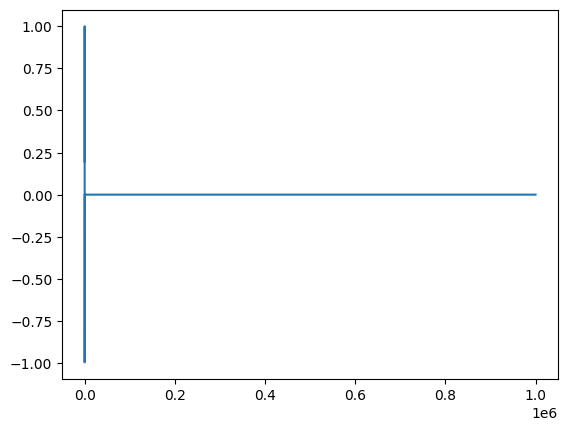

In [70]:
plt.plot(received_sig_1.real)